### 1. Research Environment Setup

BasaLens relies on a combination of machine learning, multilingual data processing, and evaluation tools. This step installs the dependencies required to conduct the experiment and develop the interactive translation interface.

Key components include Hugging Face Transformers for NLLB-200 inference, Datasets for accessing FLORES+, SacreBLEU for chrF evaluation, and Gradio for presenting the model through an interactive demonstration. The Transformers version is constrained to below version 5 to maintain compatibility with the project's implementation.

In [1]:
!pip -q install -U "transformers<5" datasets sacrebleu accelerate sentencepiece gradio

### 2. Experimental Environment and Reproducibility

This stage establishes the computational environment for the BasaLens evaluation. The experiment uses a fixed random seed (`42`) to maintain consistency in data sampling and model execution, supporting reproducibility across runs.

The required libraries provide the foundation for dataset handling, NLLB-200 inference, and chrF-based evaluation. GPU availability is also checked to determine whether accelerated inference can be used. Hugging Face authentication enables access to the pretrained model and research dataset.

In [2]:
import random
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import login
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sacrebleu.metrics import CHRF
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

login()

GPU available: True
GPU: Tesla T4


### 3. Constructing the Parallel Evaluation Dataset

To ensure a consistent comparison between English-to-Indonesian and English-to-Balinese translation, BasaLens uses the `devtest` split of the FLORES+ multilingual benchmark dataset.

The English, Indonesian, and Balinese language configurations are loaded separately and aligned using their shared sentence IDs. A one-to-one merge validation helps prevent mismatched or duplicated sentence pairs from entering the evaluation.

From the aligned dataset, 100 sentence pairs are selected using the fixed random seed (`42`). This creates a consistent evaluation sample for both translation directions, allowing their results to be compared under the same input conditions.

In [3]:
DATASET_NAME = 'openlanguagedata/flores_plus'

def load_language_split(config_name: str, output_column: str) -> pd.DataFrame:
    dataset = load_dataset(DATASET_NAME, config_name, split='devtest')
    frame = dataset.select_columns(['id', 'text']).to_pandas()
    return frame.rename(columns={'text': output_column})

english_df = load_language_split('eng_Latn', 'english')
indonesian_df = load_language_split('ind_Latn', 'indonesian_reference')
balinese_df = load_language_split('ban_Latn', 'balinese_reference')

aligned = english_df.merge(indonesian_df, on='id', how='inner', validate='one_to_one')
aligned = aligned.merge(balinese_df, on='id', how='inner', validate='one_to_one')

if len(aligned) < 100:
    raise ValueError(f'Expected at least 100 aligned rows; found {len(aligned)}. Check dataset access/config names.')


df = aligned.sample(n=100, random_state=SEED).sort_values('id').reset_index(drop=True)
print('Aligned devtest rows:', len(aligned))
print('Evaluation examples:', len(df))
display(df[['id', 'english', 'indonesian_reference', 'balinese_reference']].head(3))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Aligned devtest rows: 1012
Evaluation examples: 100


,id,english,indonesian_reference,balinese_reference
0,10,While one experimental vaccine appears able to...,Walau ada satu vaksin eksperimental yang tampa...,Yadiastun silih sinunggil experimen vaksin pra...
1,23,"Two songs from the movie, Audition (The Fools ...","Dua lagu dari film tersebut, Audition (The Foo...","2 (dua) lagu saking film tersebut, Audisi (The..."
2,30,Because the dinosaur feathers do not have a we...,Karena bulu dinosaurus tidak memiliki batang y...,Sangkaning bulu dinosauruse ten medue tunggak ...


### 4. Loading the Multilingual Translation Model

BasaLens uses Meta's NLLB-200 Distilled 600M, a pretrained neural machine translation model designed to support a wide range of languages, including Indonesian and Balinese.

The tokenizer is configured with English (`eng_Latn`) as the source language. The model's numerical precision is selected according to the available hardware: FP16 on GPU to reduce memory usage and FP32 on CPU for compatibility.

Finally, the model is moved to the selected device and placed in evaluation mode. This prepares a consistent inference environment for comparing the two target languages.

In [4]:
MODEL_NAME = 'facebook/nllb-200-distilled-600M'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_dtype = torch.float16 if device.type == 'cuda' else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, src_lang='eng_Latn')
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME, torch_dtype=model_dtype)
model.to(device)
model.eval()

print('Model loaded on:', device)

`torch_dtype` is deprecated! Use `dtype` instead!


Model loaded on: cuda


### 5. Translation Inference and Decoding Comparison

This stage implements the core experimental procedure: translating the same 100 English sentences into Indonesian and Balinese using NLLB-200.

A reusable translation function handles both target languages, processes inputs in batches, and applies the appropriate target-language token. Inference mode reduces unnecessary computational overhead during generation.

Two decoding strategies are evaluated:

- **Greedy decoding (`num_beams=1`):** selects the most probable next token at each generation step.
- **Beam search (`num_beams=4`):** explores multiple candidate sequences to identify a higher-scoring output.

This produces 400 translations in total: 100 sentences × 2 target languages × 2 decoding strategies. Keeping the source sentences and model constant allows the experiment to examine how target language and decoding strategy affect translation performance.

In [5]:
def translate_many(texts, target_language, num_beams=4, batch_size=8):
    if target_language not in {'ind_Latn', 'ban_Latn'}:
        raise ValueError('Unsupported target language code.')
    tokenizer.src_lang = 'eng_Latn'
    target_id = tokenizer.convert_tokens_to_ids(target_language)
    if target_id is None or target_id == tokenizer.unk_token_id:
        raise ValueError(f'Could not resolve target language token: {target_language}')

    predictions = []
    for start in range(0, len(texts), batch_size):
        batch_texts = [str(x) for x in texts[start:start + batch_size]]
        encoded = tokenizer(
            batch_texts, return_tensors='pt', padding=True,
            truncation=True, max_length=512
        )
        encoded = {key: value.to(device) for key, value in encoded.items()}
        with torch.inference_mode():
            generated = model.generate(
                **encoded,
                forced_bos_token_id=target_id,
                num_beams=num_beams,
                max_new_tokens=128
            )
        predictions.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))
    return predictions

# 100 English sentences × 2 target languages × 2 decoding settings = 400 translations.
for target_code, short_name in [('ind_Latn', 'indonesian'), ('ban_Latn', 'balinese')]:
    df[f'{short_name}_greedy'] = translate_many(df['english'].tolist(), target_code, num_beams=1)
    df[f'{short_name}_beam4'] = translate_many(df['english'].tolist(), target_code, num_beams=4)

display(df[['english', 'indonesian_beam4', 'balinese_beam4']].head(5))

,english,indonesian_beam4,balinese_beam4
0,While one experimental vaccine appears able to...,Sementara satu vaksin eksperimental tampaknya ...,Yadiastun wénten vaksin eksperimen sané prasid...
1,"Two songs from the movie, Audition (The Fools ...","Dua lagu dari film, Audition (The Fools Who Dr...","Kakalih tembang saking film punika, Audition (..."
2,Because the dinosaur feathers do not have a we...,Karena bulu dinosaurus tidak memiliki poros ya...,Mawinan bulu dinosaurus nénten madué poros san...
3,"During his trip, Iwasaki ran into trouble on m...","Selama perjalanannya, Iwasaki sering mengalami...","Ring sajeroning pamarginnyané, Iwasaki sering ..."
4,First among its 78 recommendations is that a n...,Pertama dari 78 rekomendasi itu adalah bahwa i...,Kawitan saking 78 rekomendasinyané inggih puni...


### 6. Quantitative Evaluation Using chrF

To measure translation quality consistently, BasaLens applies the chrF evaluation metric from SacreBLEU. chrF compares generated translations with human-written reference translations by measuring character n-gram overlap.

The evaluation is performed at the corpus level across all 100 sentences for four experimental conditions:

1. Indonesian using greedy decoding.
2. Indonesian using beam search with four beams.
3. Balinese using greedy decoding.
4. Balinese using beam search with four beams.

The resulting scores provide a quantitative basis for comparing both target languages and decoding strategies under identical evaluation conditions. Higher chrF scores indicate greater character-level similarity to the reference translations; however, they should not be interpreted as translation accuracy percentages or as a complete measure of meaning and naturalness.

In [6]:
chrf = CHRF(word_order=0)

comparisons = [
    ('Indonesian', 'indonesian_greedy', 'indonesian_reference', 'Greedy'),
    ('Indonesian', 'indonesian_beam4', 'indonesian_reference', 'Beam search (4)'),
    ('Balinese', 'balinese_greedy', 'balinese_reference', 'Greedy'),
    ('Balinese', 'balinese_beam4', 'balinese_reference', 'Beam search (4)'),
]

score_rows = []
for language, prediction_col, reference_col, method in comparisons:
    score = chrf.corpus_score(
        df[prediction_col].tolist(), [df[reference_col].tolist()]
    ).score
    score_rows.append({'Language': language, 'Method': method, 'chrF': round(score, 2)})

scores = pd.DataFrame(score_rows)
display(scores.pivot(index='Language', columns='Method', values='chrF'))

Method,Beam search (4),Greedy
Language,,
Balinese,46.41,46.81
Indonesian,69.53,69.06


### 7. Visualizing and Exporting Experimental Results

The evaluation scores are converted into a grouped bar chart to make differences between the two target languages and decoding strategies easier to interpret.

The visualization presents the chrF results from the 100-sentence evaluation sample, providing judges with a direct comparison of the four experimental conditions.

The aggregate scores are also exported to `basalens_aggregate_scores.csv` for transparent reporting and further analysis. Only the evaluation results are exported, rather than a copy of the FLORES+ source sentences.

Saved aggregate score table.


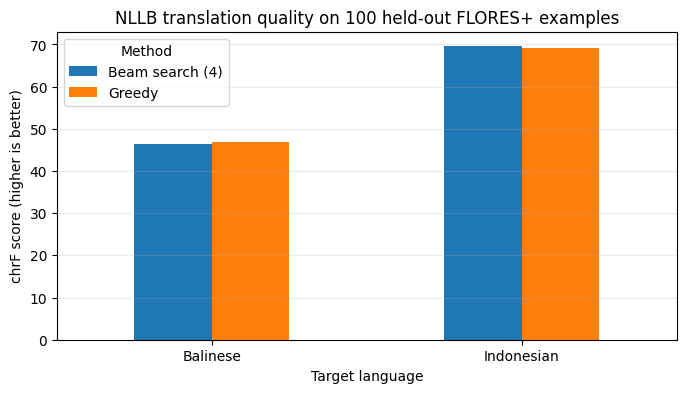

In [7]:
# Visual comparison for the notebook/demo.
plot_data = scores.pivot(index='Language', columns='Method', values='chrF')
ax = plot_data.plot(kind='bar', figsize=(8, 4))
ax.set_title('NLLB translation quality on 100 held-out FLORES+ examples')
ax.set_ylabel('chrF score (higher is better)')
ax.set_xlabel('Target language')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.25)

# Save aggregate results, not a public copy of the FLORES+ source text.
scores.to_csv('basalens_aggregate_scores.csv', index=False)
print('Saved aggregate score table.')

### 8. Identifying Potential Translation Weaknesses

Beyond overall corpus-level scores, this analysis examines individual translations to identify examples with the lowest sentence-level chrF scores for each target language.

The five lowest-scoring examples are displayed alongside their English source sentences, NLLB-generated translations, and reference translations. This makes it possible to investigate potential weaknesses that may be hidden by aggregate results.

Each example should be examined for possible differences in meaning, word choice, names, numbers, language register, and grammatical structure. These cases are intended to guide qualitative error analysis, rather than automatically classify every low-scoring translation as incorrect.

In [8]:
for language, prediction_col, reference_col, score_col in [
    ('Balinese', 'balinese_beam4', 'balinese_reference', 'balinese_beam4_chrf'),
    ('Indonesian', 'indonesian_beam4', 'indonesian_reference', 'indonesian_beam4_chrf')
]:
    df[score_col] = [
        chrf.sentence_score(hyp, [ref]).score
        for hyp, ref in zip(df[prediction_col], df[reference_col])
    ]

    print(f'Five lowest-scoring {language} examples:')
    display(
        df.nsmallest(5, score_col)[
            ['english', prediction_col, reference_col, score_col]
        ].rename(columns={prediction_col: 'NLLB output', reference_col: 'Reference', score_col: 'sentence chrF'})
    )

    print('Discuss whether the problem is meaning, word choice, names/numbers, register, or grammar.')

Five lowest-scoring Balinese examples:


,english,NLLB output,Reference,sentence chrF
37,He is speculated to make a run for president i...,Dané kawedar pacang malaib dados présidén ring...,Ipune makayun prasida newek nyalonin indik pam...,19.015093
56,"Germany was a common enemy in World War 2, lea...",Jerman inggih punika musuh sané pateh ring Per...,Jerman wantah musuh bersamanyane ring Perang D...,25.139486
48,Up means you should start at the tip and push ...,Ngiring munggah artosnyané mangda ngawit sakin...,Marep menek maarti ida dane patut nyumunin sak...,27.477046
83,The idea of skiing is very old — cave painting...,Gagasan ski inggih punika lukisan gua sané sam...,Ide antuk main ski wantah kuna pisan - gambara...,28.321034
97,It has a notably wide variety of plant communi...,"Puniki madué makudang-kudang entikan entikan, ...",Puniki madue sekancan jenis pepunyanan sane ma...,29.252024


Discuss whether the problem is meaning, word choice, names/numbers, register, or grammar.
Five lowest-scoring Indonesian examples:


,english,NLLB output,Reference,sentence chrF
74,It was one of the major stops during Henry Lou...,Ini adalah salah satu halte utama selama acara...,Situs ini merupakan salah satu perhentian utam...,36.332899
9,After a week of losses in the midterm election...,Setelah seminggu kalah dalam pemilihan paruh w...,"Setelah sepekan gagal pada pemilu pertengahan,...",48.016148
81,Posted speed limits are noticeably lower than ...,Batas kecepatan yang ditampilkan jauh lebih re...,Batasan kecepatan yang ada lebih rendah diband...,51.326484
46,Since there was limited response to this tacti...,Karena ada respons terbatas terhadap taktik in...,"Akibat respons yang terbatas atas taktik ini, ...",51.378537
26,The bill requires violent video games sold in ...,RUU itu mengharuskan video game kekerasan yang...,"""Undang-Undang menuntut agar permainan video k...",51.398906


Discuss whether the problem is meaning, word choice, names/numbers, register, or grammar.


### 9. Human Review of Balinese Translation Quality

Automated metrics alone cannot fully assess whether a translation preserves meaning or sounds natural to native speakers. To complement the chrF evaluation, this stage prepares a sample of up to 25 Balinese translations for qualitative human review.

The sample is selected using a fixed random seed (`17`) to maintain consistency. A simple three-level rubric is provided to assess each translation:

- **0 — Incorrect or unusable:** The translation fails to communicate the intended meaning.
- **1 — Partially correct or awkward:** The general meaning is understandable, but significant issues remain.
- **2 — Clear and natural:** The translation communicates the intended meaning clearly and naturally.

This review provides an additional perspective on translation quality that character-level similarity scores cannot capture. It is exploratory feedback, not a formal or representative evaluation of all Balinese speakers.

In [9]:
review_sample = df.sample(n=min(25, len(df)), random_state=17).sort_values('id')
display(review_sample[['id', 'english', 'balinese_beam4']].reset_index(drop=True))
print('Reviewer rubric: 0 = wrong/unusable; 1 = partly correct/awkward; 2 = clear and natural.')

,id,english,balinese_beam4
0,54,First among its 78 recommendations is that a n...,Kawitan saking 78 rekomendasinyané inggih puni...
1,70,After a week of losses in the midterm election...,"Risampuné wuku ical ring pemilu pertengahan, B..."
2,107,A doctor who worked at Children's Hospital of ...,Dokter sané makarya ring Rumah Sakit Kanak-kan...
3,174,Bishkek was described as sinking into a state ...,"Bishkek kacritayang dados ""anarki"" olih sinali..."
4,199,"With only eighteen medals available a day, a n...",Wantah 18 medali sané prasida kapolihang nyabr...
5,280,Police superintendent Chandra Shekhar Solanki ...,Superintendent polisi Chandra Shekhar Solanki ...
6,314,Liggins followed in his father’s footsteps and...,Liggins nututin jejak bapane lan ngranjing kar...
7,321,"Dustin ""Goldust"" Runnels commented that ""Luna ...","Dustin ""Goldust"" Runnels maosang indik ""Luna w..."
8,334,He is speculated to make a run for president i...,Dané kawedar pacang malaib dados présidén ring...
9,365,Lion prides act much like packs of wolves or d...,Singa bangga malaksana sakadi pakumpulan serig...


Reviewer rubric: 0 = wrong/unusable; 1 = partly correct/awkward; 2 = clear and natural.


### 10. Real-World Application: School Notice Translation

To explore how BasaLens performs beyond benchmark data, this stage tests the model using 10 original English school notices covering everyday school communication.

The notices are translated into Indonesian and Balinese using beam search with four beams. The resulting translations are displayed side by side to examine how the model handles practical expressions, institutional terminology, instructions, and context-dependent vocabulary.

This experiment demonstrates a potential application of multilingual AI translation in educational environments. These examples are exploratory demonstrations and should be reviewed by fluent speakers before being used in official school communication.

In [10]:
local_notices = [
    'The school library will be closed on Friday.',
    'Please return borrowed books before the end of the week.',
    'The student meeting will begin at eight in the morning.',
    'Parents are invited to attend the school performance.',
    'Please keep the classroom clean after the activity.',
    'The event has been moved to the school hall because of rain.',
    'Students should arrive fifteen minutes before the ceremony.',
    'Please contact the school office if you have any questions.',
    'The lost-and-found desk is beside the main entrance.',
    'Thank you for helping keep our school community safe.'
]
local_df = pd.DataFrame({'english': local_notices})
local_df['nllb_indonesian'] = translate_many(local_notices, 'ind_Latn', num_beams=4, batch_size=4)
local_df['nllb_balinese'] = translate_many(local_notices, 'ban_Latn', num_beams=4, batch_size=4)
display(local_df)

,english,nllb_indonesian,nllb_balinese
0,The school library will be closed on Friday.,Perpustakaan sekolah akan ditutup pada hari Ju...,Perpustakaan sekolah pacang puput rahina Redit...
1,Please return borrowed books before the end of...,Silahkan kembalikan buku yang dipinjam sebelum...,Mangda baliang cakepan sané kautang sadurung p...
2,The student meeting will begin at eight in the...,Pertemuan siswa akan dimulai pukul delapan pagi.,Rapat mahasiswa pacang kakawitin jam kutus sem...
3,Parents are invited to attend the school perfo...,Orang tua diundang untuk menghadiri pertunjuka...,Para rerama kaundang mangda nyarengin pagelara...
4,Please keep the classroom clean after the acti...,Silakan menjaga ruang kelas bersih setelah keg...,Mangda kamar kelas tetep bersih sasampun kegia...
5,The event has been moved to the school hall be...,Acara ini telah dipindahkan ke aula sekolah ka...,Acara puniki kaangkat ka aula sekolah sangkani...
6,Students should arrive fifteen minutes before ...,Siswa harus tiba 15 menit sebelum upacara.,Siswa patut rauh limalas menit sadurung upacara.
7,Please contact the school office if you have a...,Silakan hubungi kantor sekolah jika Anda memil...,Mangda polih pitaken ring kantor sekolah yenin...
8,The lost-and-found desk is beside the main ent...,Meja yang hilang dan ditemukan berada di sebel...,Méja sané ical miwah kapanggih wénten ring sam...
9,Thank you for helping keep our school communit...,Terima kasih telah membantu menjaga komunitas ...,Suksma antuk nulungin ngajaga komunitas sekola...


### 11. Interactive Demonstration with Gradio

This stage transforms the trained inference pipeline into an interactive demonstration, allowing judges to test BasaLens using their own English input.

The interface provides two translation targets: Balinese (*Basa Bali*) and Indonesian (*Bahasa Indonesia*). Users can enter a sentence, select the desired language, and receive an AI-generated translation using the same NLLB-200 model and beam-search configuration used in the evaluation.

The Gradio interface makes the research accessible beyond the notebook by allowing direct interaction with the system. It also clearly identifies the output as an AI translation draft, emphasizing the importance of fluent-speaker review for important communication.

In [11]:
import gradio as gr

def demo_translate(text, target_language):
    if not text or not text.strip():
        return 'Please enter a sentence first.'
    target_code = {
        'Balinese (Basa Bali)': 'ban_Latn',
        'Indonesian (Bahasa Indonesia)': 'ind_Latn'
    }[target_language]
    return translate_many([text.strip()], target_code, num_beams=4, batch_size=1)[0]

demo = gr.Interface(
    fn=demo_translate,
    inputs=[
        gr.Textbox(lines=4, label='English source text', placeholder='Type a short school or community notice...'),
        gr.Dropdown(
            choices=['Balinese (Basa Bali)', 'Indonesian (Bahasa Indonesia)'],
            value='Balinese (Basa Bali)', label='Translate into'
        )
    ],
    outputs=gr.Textbox(lines=5, label='AI translation draft'),
    title='BasaLens',
    description='A research prototype comparing AI translation into Balinese and Indonesian. Have a fluent speaker review important text.'
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://07ed88e75baef71c14.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Environment Compatibility Adjustment

Upgrade the Protobuf dependency to resolve a version incompatibility encountered when loading the pretrained language-identification model. This ensures that the runtime environment can correctly load the model's tokenizer and SentencePiece components.

In [12]:
!pip install -U "protobuf>=7.36.1"

ERROR: Operation cancelled by user


### 13. Validating the Language Identification Classifier

Before using automated language identification to analyze NLLB-200 outputs, the selected XLM-RoBERTa classifier is evaluated against known Balinese and Indonesian reference translations from the FLORES+ dataset.

A validation set containing 100 sentences per language is constructed and shuffled using a fixed random seed. The classifier predicts the language of each sentence, and its predictions are compared with the known language labels.

Overall accuracy and a confusion matrix are generated to measure how reliably the classifier distinguishes Balinese from Indonesian. This validation is essential because errors made by the classifier could otherwise lead to misleading conclusions about NLLB-200's translation behavior.

In [13]:
from transformers import pipeline

LID_MODEL_NAME = 'nahiar/xlm-roberta-indonesian-languages'

lid_classifier = pipeline(
    'text-classification',
    model=LID_MODEL_NAME,
    device=-1
)

# Build a validation set from known reference translations.
validation_df = pd.concat([
    pd.DataFrame({
        'text': df['balinese_reference'],
        'true_language': 'balinese'
    }),
    pd.DataFrame({
        'text': df['indonesian_reference'],
        'true_language': 'indonesian'
    })
], ignore_index=True)

validation_df = validation_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Predict the language of each reference.
predictions = lid_classifier(
    validation_df['text'].tolist(),
    batch_size=16,
    truncation=True
)

validation_df['predicted_language'] = [
    result['label'].lower() for result in predictions
]

# Evaluate classifier performance.
validation_df['correct'] = (
    validation_df['true_language']
    == validation_df['predicted_language']
)

print('Reference validation accuracy:',
      round(validation_df['correct'].mean() * 100, 2), '%')

display(pd.crosstab(
    validation_df['true_language'],
    validation_df['predicted_language'],
    rownames=['Actual language'],
    colnames=['Predicted language']
))

Device set to use cpu


Reference validation accuracy: 92.5 %


Predicted language,balinese,banjarese,english,indonesian,javanese,madurese,ngaju,toba_batak
Actual language,,,,,,,,
balinese,88,3,0,0,5,1,2,1
indonesian,0,0,2,97,0,1,0,0


### 14. Detecting Language Distribution in Balinese Model Outputs

After validating the language-identification classifier, it is applied to all 100 Balinese translations generated by NLLB-200 using beam search with four beams.

Each generated sentence is classified into one of the supported regional languages. The results are then aggregated into sentence counts and percentages to examine the linguistic composition of the model's outputs.

Particular attention is given to Indonesian-language leakage, which could indicate that the model produces Indonesian instead of the intended Balinese translation.

This analysis provides an additional dimension of evaluation beyond chrF, helping investigate whether low translation similarity may be associated with language confusion. Classifier predictions remain indicative rather than definitive because the validation results show that some genuine Balinese references are misclassified.

In [14]:
# Detect language distribution in NLLB-generated Balinese translations.

balinese_outputs = df['balinese_beam4'].fillna('').tolist()

balinese_predictions = lid_classifier(
    balinese_outputs,
    batch_size=16,
    truncation=True
)

df['detected_language'] = [
    result['label'].lower()
    for result in balinese_predictions
]

language_distribution = (
    df['detected_language']
    .value_counts()
    .rename_axis('Detected language')
    .reset_index(name='Number of sentences')
)

language_distribution['Percentage'] = (
    language_distribution['Number of sentences'] / len(df) * 100
).round(2)

display(language_distribution)

print(
    'Predicted Indonesian leakage:',
    (df['detected_language'] == 'indonesian').sum(),
    'out of',
    len(df)
)

,Detected language,Number of sentences,Percentage
0,balinese,93,93.0
1,javanese,5,5.0
2,sundanese,2,2.0


Predicted Indonesian leakage: 0 out of 100


In [15]:
banjar_notices = [
    # Community meetings
    "The monthly community meeting will be held on Saturday at seven in the evening.",
    "All residents are invited to attend the upcoming community meeting.",
    "Please arrive on time for the community discussion at the village hall.",
    "The meeting agenda will include community safety and upcoming activities.",
    "Residents who cannot attend the meeting should inform the community secretary.",

    # Religious and cultural events
    "The temple ceremony will begin early tomorrow morning.",
    "All families are invited to participate in the upcoming religious celebration.",
    "Please bring the required offerings before the ceremony begins.",
    "Residents are requested to help prepare the temple area for the celebration.",
    "The cultural performance will take place after the evening prayer.",

    # Community activities
    "Community members will work together to clean the village environment on Sunday.",
    "Volunteers are needed to help prepare the community hall for the event.",
    "Please bring cleaning equipment for the scheduled community activity.",
    "The youth organization will organize a traditional cultural performance.",
    "Residents are encouraged to participate in the village sports competition.",

    # Public information
    "The main road will be temporarily closed because of community preparations.",
    "Please use the alternative route while road maintenance is taking place.",
    "The community health service will be available at the village hall tomorrow.",
    "Residents can collect important announcements from the community office.",
    "Please contact the community secretary for further information.",

    # Reminders and instructions
    "Please keep the community hall clean after every activity.",
    "Residents are reminded to dispose of waste in the designated containers.",
    "Please switch off the lights after using the meeting hall.",
    "All participants should register before joining the community event.",
    "Thank you for your cooperation in maintaining a safe and welcoming community."
]

print("Total banjar announcements:", len(banjar_notices))

Total banjar announcements: 25


In [16]:
banjar_df = pd.DataFrame({
    'id': range(1, len(banjar_notices) + 1),
    'english': banjar_notices
})

banjar_df['nllb_balinese'] = translate_many(
    banjar_df['english'].tolist(),
    'ban_Latn',
    num_beams=4,
    batch_size=4
)

display(banjar_df)

,id,english,nllb_balinese
0,1,The monthly community meeting will be held on ...,Rapat komunitas bulanan pacang kamargiang ring...
1,2,All residents are invited to attend the upcomi...,Makasami krama kaundang mangda nyarengin pawiw...
2,3,Please arrive on time for the community discus...,Mangda rauh ring galah antuk diskusi komunitas...
3,4,The meeting agenda will include community safe...,Agenda patemon pacang ngranjing kaamanan komun...
4,5,Residents who cannot attend the meeting should...,Warga sané nénten prasida nyarengin patemon pu...
5,6,The temple ceremony will begin early tomorrow ...,Upacara ring pura pacang kakawitin pasemengan ...
6,7,All families are invited to participate in the...,Makasami kulawarga kaundang nyarengin perayaan...
7,8,Please bring the required offerings before the...,Mangda makta aturan sané kaaptiang sadurung up...
8,9,Residents are requested to help prepare the te...,Wargi kaundang mangda nulungin nyiapang wewida...
9,10,The cultural performance will take place after...,Acara budaya pacang kamargiang sasampun sembah...


In [17]:
# Prepare an independent human-reference worksheet.

reference_sheet = banjar_df[
    ['id', 'english']
].copy()

reference_sheet['human_balinese_reference'] = ''

reference_sheet.to_csv(
    'basalens_banjar_human_reference.csv',
    index=False
)

print("Human-reference worksheet created.")
display(reference_sheet.head())

Human-reference worksheet created.


,id,english,human_balinese_reference
0,1,The monthly community meeting will be held on ...,
1,2,All residents are invited to attend the upcomi...,
2,3,Please arrive on time for the community discus...,
3,4,The meeting agenda will include community safe...,
4,5,Residents who cannot attend the meeting should...,


In [18]:
# Compare NLLB translations with independent human references.

human_references = [
    "Rapat komunitas ring sasih puniki bakal kalaksanayang ring Rahina Saniscara jam pitu wonten dalu.",
    "Saking sedaging warga taler katundang mantuka rawuh ring rapat komunitas sane rauh.",
    "Mangda rauh ring waktu kanggo rembugan krama ring balai banjar.",
    "Agenda rapat puniki taler ngelaksanayang keamanan krama miwah kegiatan sane rauh.",
    "Warga sane nenten dados rawuh ring rapat kudang ngametuangang ring sekretaris banjar.",
    "Upacara pura bakal prasida taler ritatkala isuk ring rahina puniki.",
    "Sakewala kulawarga katampi nyakut nglaksanayang perayaan agama sane rauh.",
    "Mangda nentenang sesajen sane kasuratang sadurung upacara ngametuang.",
    "Warga kapanggih ngewakin nyidang nglaksanayang areal pura kangge perayaan.",
    "Pertunjukan budaya puniki prasida kadadosang sasampun sembahyang ring rahina malem",
    "Warga banjar bakal kerja bareng-bareng ngresiki lingkungan desa ring hari Minggu.",
    "Sukarela prasida kapanggihang mantuk nyiapang aula komunitas kangge acara puniki.",
    "Mangda nentenangang peralatan resik-resik ring acara krama sane sampun kadadosang.",
    "Organisasi muda puniki pacang ngatur pagelahan budaya tradisional.",
    "Warga dianjurang taler melu nyarengin lomba olahraga banjar.",
    "Jalan utama bakal taler katutup sakewala awit nyantosang persiapan krama.",
    "Mangda prasida taler nganggé jalur liya madaging indik perawatan jalan.",
    "Layanan kesehatan taler ring krama nyantosang ring balai desa ring rahina menjange.",
    "Warga nenten prasida nglumpukang pawarta penting ring kantor banjar.",
    "Mangda hubungi sekretaris komunitas ring indik indik sane malih.",
    "Mangda nenten lali ngresiki balai banjar sajeroning prasida ngemargiang kegiatan.",
    "Warga prasida taler ngelingang nyidang nyimpen sampah ring wadah sane sampun kapilih.",
    "Tolong matengin lampu sawireh nyantosang nganggengin gedung rapat.",
    "Sakewala peserta prasida ndaftar ragan malih dados nglaksanayang acara komunitas.",
    "Matur suksma ring kerjasama sareng nglestarikeun komunitas sane aman miwah nyamengin."
]

# Attach references using matching IDs.
banjar_df['human_balinese_reference'] = human_references

# Calculate corpus-level chrF.
banjar_chrf = chrf.corpus_score(
    banjar_df['nllb_balinese'].tolist(),
    [banjar_df['human_balinese_reference'].tolist()]
)

print("Banjar announcement evaluation")
print("Number of sentences:", len(banjar_df))
print("NLLB vs human-reference chrF:", round(banjar_chrf.score, 2))

# Calculate sentence-level chrF scores.
banjar_df['sentence_chrf'] = [
    chrf.sentence_score(prediction, [reference]).score
    for prediction, reference in zip(
        banjar_df['nllb_balinese'],
        banjar_df['human_balinese_reference']
    )
]

display(
    banjar_df[
        ['id', 'english', 'nllb_balinese',
         'human_balinese_reference', 'sentence_chrf']
    ].sort_values('sentence_chrf')
)

Banjar announcement evaluation
Number of sentences: 25
NLLB vs human-reference chrF: 41.01


,id,english,nllb_balinese,human_balinese_reference,sentence_chrf
5,6,The temple ceremony will begin early tomorrow ...,Upacara ring pura pacang kakawitin pasemengan ...,Upacara pura bakal prasida taler ritatkala isu...,23.071315
20,21,Please keep the community hall clean after eve...,Mangda kamaré puniki setata bersih sasampun pu...,Mangda nenten lali ngresiki balai banjar sajer...,24.463089
16,17,Please use the alternative route while road ma...,Mangda nganggén rute alternatif ri tatkala pan...,Mangda prasida taler nganggé jalur liya madagi...,30.695273
21,22,Residents are reminded to dispose of waste in ...,Wargi kainget mangda ngicalang limbah ring wad...,Warga prasida taler ngelingang nyidang nyimpen...,32.170160
8,9,Residents are requested to help prepare the te...,Wargi kaundang mangda nulungin nyiapang wewida...,Warga kapanggih ngewakin nyidang nglaksanayang...,34.429700
22,23,Please switch off the lights after using the m...,Mangda matiang lampu sasampun nganggen ruang r...,Tolong matengin lampu sawireh nyantosang ngang...,36.068613
2,3,Please arrive on time for the community discus...,Mangda rauh ring galah antuk diskusi komunitas...,Mangda rauh ring waktu kanggo rembugan krama r...,36.280801
17,18,The community health service will be available...,Layanan kesehatan masyarakat pacang wénten rin...,Layanan kesehatan taler ring krama nyantosang ...,36.526693
23,24,All participants should register before joinin...,Makasami peserta patut matetapang sadurung nya...,Sakewala peserta prasida ndaftar ragan malih d...,36.845628
1,2,All residents are invited to attend the upcomi...,Makasami krama kaundang mangda nyarengin pawiw...,Saking sedaging warga taler katundang mantuka ...,37.930865


### Human Evaluation of Translation Quality

To complement automatic chrF evaluation, human assessment is used to examine the semantic accuracy and linguistic naturalness of BasaLens translations.

Each translation should be evaluated by a fluent Balinese speaker using the following criteria:

| Criterion | Score | Description |
|---|---:|---|
| Meaning | 1–5 | How accurately does the translation preserve the original English meaning? |
| Fluency | 1–5 | How natural and grammatically appropriate is the Balinese translation? |
| Language consistency | 1–5 | How consistently does the translation use Balinese rather than Indonesian vocabulary or structures? |

**Scoring guide:**
- 1 — Very poor
- 2 — Poor
- 3 — Acceptable
- 4 — Good
- 5 — Excellent

The evaluator should also identify whether each translation is suitable for its intended purpose: communicating community announcements to local residents.

Human evaluation is important because a translation may achieve a reasonable chrF score while still containing unnatural expressions, altered meanings, or inappropriate language choices.

In [19]:
meaning=[5,3,4,2,2,2,1,2,1,4,5,3,2,4,4,3,3,2,1,4,3,2,2,1,4]
fluency=[3,2,3,2,2,2,1,2,1,3,3,2,2,3,2,2,2,2,2,2,3,2,2,1,3]
cons=[3,3,3,3,3,3,3,3,3,3,2,2,3,3,2,3,2,2,3,2,3,3,1,2,3]
import statistics
[len(x) for x in [meaning,fluency,cons]], [sum(x)/len(x) for x in [meaning,fluency,cons]], sum(meaning+fluency+cons)/75


([25, 25, 25], [2.76, 2.16, 2.64], 2.52)

### Error Taxonomy: Identifying Translation Weaknesses

Human evaluation revealed several recurring error categories in NLLB-generated Balinese translations.

| Error category | Description | Examples |
|---|---|---|
| Semantic errors | The translation changes or fails to preserve the original meaning. | IDs 4, 7, 9 |
| Negation errors | Negation is introduced or used incorrectly, potentially reversing the instruction. | IDs 8, 19, 23 |
| Indonesian language interference | Indonesian vocabulary or sentence structures appear in the Balinese output. | IDs 10, 11, 18, 20 |
| Lexical errors | Individual words are translated incorrectly or used in an inappropriate context. | IDs 5, 6, 22 |
| Grammatical and fluency errors | The sentence is unnatural, incoherent, or grammatically inappropriate. | IDs 2, 7, 9, 24 |
| Register and formality issues | Word choices do not consistently match the formal tone expected in community announcements. | IDs 1, 3 |

These categories are not mutually exclusive. A single translation may contain multiple types of errors.

The findings indicate that BasaLens requires improvements in semantic preservation, vocabulary selection, grammatical fluency, and appropriate Balinese language usage.

In [20]:
# Test beam search with a larger beam size.

banjar_df['nllb_balinese_beam8'] = translate_many(
    banjar_df['english'].tolist(),
    'ban_Latn',
    num_beams=8,
    batch_size=4
)

# Evaluate beam 8 against the same human references.
beam8_score = chrf.corpus_score(
    banjar_df['nllb_balinese_beam8'].tolist(),
    [banjar_df['human_balinese_reference'].tolist()]
)

print("Beam 4 chrF:", round(banjar_chrf.score, 2))
print("Beam 8 chrF:", round(beam8_score.score, 2))

print(
    "Difference:",
    round(beam8_score.score - banjar_chrf.score, 2),
    "chrF points"
)

display(
    banjar_df[
        ['id', 'english', 'nllb_balinese',
         'nllb_balinese_beam8', 'human_balinese_reference']
    ].head(10)
)

Beam 4 chrF: 41.01
Beam 8 chrF: 40.77
Difference: -0.24 chrF points


,id,english,nllb_balinese,nllb_balinese_beam8,human_balinese_reference
0,1,The monthly community meeting will be held on ...,Rapat komunitas bulanan pacang kamargiang ring...,Rapat komunitas bulanan pacang kamargiang ring...,Rapat komunitas ring sasih puniki bakal kalaks...
1,2,All residents are invited to attend the upcomi...,Makasami krama kaundang mangda nyarengin pawiw...,Makasami krama kaundang mangda nyarengin pawiw...,Saking sedaging warga taler katundang mantuka ...
2,3,Please arrive on time for the community discus...,Mangda rauh ring galah antuk diskusi komunitas...,Mangda rauh ring galah antuk diskusi komunitas...,Mangda rauh ring waktu kanggo rembugan krama r...
3,4,The meeting agenda will include community safe...,Agenda patemon pacang ngranjing kaamanan komun...,Agenda patemon pacang ngranjing kaamanan komun...,Agenda rapat puniki taler ngelaksanayang keama...
4,5,Residents who cannot attend the meeting should...,Warga sané nénten prasida nyarengin patemon pu...,Warga sané nénten prasida nyarengin patemon pu...,Warga sane nenten dados rawuh ring rapat kudan...
5,6,The temple ceremony will begin early tomorrow ...,Upacara ring pura pacang kakawitin pasemengan ...,Upacara ring pura pacang kakawitin pasemengan ...,Upacara pura bakal prasida taler ritatkala isu...
6,7,All families are invited to participate in the...,Makasami kulawarga kaundang nyarengin perayaan...,Makasami kulawarga kaundang nyarengin perayaan...,Sakewala kulawarga katampi nyakut nglaksanayan...
7,8,Please bring the required offerings before the...,Mangda makta aturan sané kaaptiang sadurung up...,Mangda makta aturan sané kaaptiang sadurung up...,Mangda nentenang sesajen sane kasuratang sadur...
8,9,Residents are requested to help prepare the te...,Wargi kaundang mangda nulungin nyiapang wewida...,Wargi kaundang mangda nulungin nyiapang wewida...,Warga kapanggih ngewakin nyidang nglaksanayang...
9,10,The cultural performance will take place after...,Acara budaya pacang kamargiang sasampun sembah...,Kinerja budaya pacang kamargiang sasampun semb...,Pertunjukan budaya puniki prasida kadadosang s...


### Decoding Strategy Experiment: Beam 4 vs. Beam 8

An additional experiment was conducted to investigate whether increasing the beam-search size could improve English-to-Balinese translation quality.

| Decoding strategy | chrF score |
|---|---:|
| Beam search (4) | 41.01 |
| Beam search (8) | 40.77 |

Increasing the beam size from 4 to 8 resulted in a decrease of 0.24 chrF points.

**Interpretation:** A larger beam size did not improve translation similarity to the human references in this experiment. The result suggests that increasing the number of candidate sequences alone is insufficient to address the model's linguistic and semantic weaknesses.

The small difference should be interpreted cautiously. Further evaluation would be needed to determine whether this change is meaningful.

In [21]:
# Compare beam 4 and beam 8 translation outputs.

banjar_df['outputs_differ'] = (
    banjar_df['nllb_balinese'].str.strip()
    != banjar_df['nllb_balinese_beam8'].str.strip()
)

different_outputs = banjar_df['outputs_differ'].sum()
identical_outputs = len(banjar_df) - different_outputs

print("Total announcements:", len(banjar_df))
print("Identical translations:", identical_outputs)
print("Different translations:", different_outputs)

print(
    "Percentage of different outputs:",
    round(different_outputs / len(banjar_df) * 100, 2),
    "%"
)

display(
    banjar_df.loc[
        banjar_df['outputs_differ'],
        ['id', 'english', 'nllb_balinese',
         'nllb_balinese_beam8']
    ]
)

Total announcements: 25
Identical translations: 19
Different translations: 6
Percentage of different outputs: 24.0 %


,id,english,nllb_balinese,nllb_balinese_beam8
9,10,The cultural performance will take place after...,Acara budaya pacang kamargiang sasampun sembah...,Kinerja budaya pacang kamargiang sasampun semb...
12,13,Please bring cleaning equipment for the schedu...,Mangda makta peralatan kebersihan antuk kegiat...,Mangda makta peralatan pembersih antuk kegiata...
13,14,The youth organization will organize a traditi...,Organisasi nonoman pacang ngamolihang pagelara...,Organisasi para yowana pacang ngwentenang acar...
16,17,Please use the alternative route while road ma...,Mangda nganggén rute alternatif ri tatkala pan...,Mangda nganggén rute alternatif ri tatkala pan...
20,21,Please keep the community hall clean after eve...,Mangda kamaré puniki setata bersih sasampun pu...,Mangda kamar komunitas tetep resik sasampuné n...
21,22,Residents are reminded to dispose of waste in ...,Wargi kainget mangda ngicalang limbah ring wad...,Wargi-wargi kainget mangda ngicalang limbah ri...


### Translation Output Consistency: Beam 4 vs. Beam 8

A sentence-level comparison was conducted to examine how increasing the beam size affected generated translations.

| Observation | Result |
|---|---:|
| Total announcements | 25 |
| Identical outputs | 19 (76%) |
| Different outputs | 6 (24%) |

Most translations remained unchanged when the beam size increased from 4 to 8.

Although six translations changed, the overall chrF score decreased slightly from 41.01 to 40.77.

**Interpretation:** Increasing the beam size had a limited effect on the generated outputs and did not produce an improvement in aggregate translation similarity. This reinforces the finding that decoding adjustments alone may not resolve the model's weaknesses in Balinese translation.

In [22]:
# Bootstrap confidence interval for the chrF difference.

import numpy as np

N_BOOTSTRAP = 2000
bootstrap_differences = []

references = banjar_df['human_balinese_reference'].tolist()
beam4_outputs = banjar_df['nllb_balinese'].tolist()
beam8_outputs = banjar_df['nllb_balinese_beam8'].tolist()

rng = np.random.default_rng(SEED)

for _ in range(N_BOOTSTRAP):
    indices = rng.integers(0, len(references), len(references))

    sampled_references = [references[i] for i in indices]
    sampled_beam4 = [beam4_outputs[i] for i in indices]
    sampled_beam8 = [beam8_outputs[i] for i in indices]

    score4 = chrf.corpus_score(
        sampled_beam4,
        [sampled_references]
    ).score

    score8 = chrf.corpus_score(
        sampled_beam8,
        [sampled_references]
    ).score

    bootstrap_differences.append(score8 - score4)

ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

print("Observed difference (Beam 8 - Beam 4):",
      round(beam8_score.score - banjar_chrf.score, 2))

print("95% Bootstrap confidence interval:")
print(f"[{ci_lower:.2f}, {ci_upper:.2f}]")

Observed difference (Beam 8 - Beam 4): -0.24
95% Bootstrap confidence interval:
[-1.00, 0.30]


### Statistical Uncertainty: Bootstrap Confidence Interval

A bootstrap analysis with 2,000 resampling iterations was conducted to estimate the uncertainty of the chrF difference between beam 4 and beam 8.

| Measurement | Result |
|---|---:|
| Observed difference (Beam 8 − Beam 4) | -0.24 |
| 95% bootstrap confidence interval | [-1.00, 0.30] |

**Interpretation:** The confidence interval includes zero, indicating that the observed difference does not provide sufficient evidence of a consistent performance advantage for either decoding strategy.

The results suggest that increasing the beam size from 4 to 8 does not demonstrate a reliable improvement in translation similarity within this 25-sentence evaluation.

**Limitation:** The evaluation uses only 25 custom community announcements and one human reference per sentence. The confidence interval reflects sentence-level resampling uncertainty, not variation across different speakers or datasets.

In [23]:
# Consolidate the main experimental findings.

results_summary = pd.DataFrame([
    {
        'Experiment': 'FLORES+ English-Balinese',
        'Evaluation': 'chrF',
        'Result': '46.81 (Greedy), 46.41 (Beam 4)'
    },
    {
        'Experiment': 'FLORES+ English-Indonesian',
        'Evaluation': 'chrF',
        'Result': '69.06 (Greedy), 69.53 (Beam 4)'
    },
    {
        'Experiment': 'Language identification validation',
        'Evaluation': 'Accuracy',
        'Result': '92.50%'
    },
    {
        'Experiment': 'Balinese output language identification',
        'Evaluation': 'Predicted language distribution',
        'Result': '93% Balinese, 5% Javanese, 2% Sundanese'
    },
    {
        'Experiment': 'Banjar announcements',
        'Evaluation': 'chrF',
        'Result': f'Beam 4: {banjar_chrf.score:.2f}'
    },
    {
        'Experiment': 'Human evaluation',
        'Evaluation': 'Overall average',
        'Result': '2.52 / 5'
    },
    {
        'Experiment': 'Human evaluation',
        'Evaluation': 'Suitable after edits',
        'Result': '9 / 25'
    },
    {
        'Experiment': 'Beam 4 vs. Beam 8',
        'Evaluation': 'chrF difference',
        'Result': f'{beam8_score.score - banjar_chrf.score:.2f}'
    },
    {
        'Experiment': 'Bootstrap analysis',
        'Evaluation': '95% confidence interval',
        'Result': f'[{ci_lower:.2f}, {ci_upper:.2f}]'
    }
])

display(results_summary)

,Experiment,Evaluation,Result
0,FLORES+ English-Balinese,chrF,"46.81 (Greedy), 46.41 (Beam 4)"
1,FLORES+ English-Indonesian,chrF,"69.06 (Greedy), 69.53 (Beam 4)"
2,Language identification validation,Accuracy,92.50%
3,Balinese output language identification,Predicted language distribution,"93% Balinese, 5% Javanese, 2% Sundanese"
4,Banjar announcements,chrF,Beam 4: 41.01
5,Human evaluation,Overall average,2.52 / 5
6,Human evaluation,Suitable after edits,9 / 25
7,Beam 4 vs. Beam 8,chrF difference,-0.24
8,Bootstrap analysis,95% confidence interval,"[-1.00, 0.30]"


## Overall Research Findings

The experiments investigated the translation capabilities of NLLB-200 for English-to-Balinese translation, using Indonesian as a comparison language.

### 1. Translation Quality

On the 100-sentence FLORES+ evaluation sample, English-to-Balinese translation achieved chrF scores of 46.81 with greedy decoding and 46.41 with beam search (4). English-to-Indonesian achieved higher scores of 69.06 and 69.53, respectively.

This indicates a substantial difference in translation similarity between the two target languages within this evaluation sample.

### 2. Language Identification

The language identification classifier achieved 92.50% accuracy on the reference validation set. Among the 100 generated Balinese translations, 93% were classified as Balinese, 5% as Javanese, and 2% as Sundanese.

No outputs were classified as Indonesian. However, the classifier's imperfect validation performance means these predictions should not be treated as definitive proof of language correctness.

### 3. Real-World Human Evaluation

A separate evaluation using 25 community announcements produced a beam 4 chrF score of 41.01.

Human assessment resulted in an overall average of 2.52 out of 5 across meaning preservation, fluency, and Balinese language consistency. Only 9 of the 25 translations were considered usable after editing.

Recurring problems included semantic errors, incorrect negation, Indonesian-influenced vocabulary, and unnatural sentence structures.

### 4. Decoding Strategy Experiment

Increasing the beam size from 4 to 8 reduced the chrF score by 0.24 points. Although 6 of the 25 translations changed, 19 remained identical.

The 95% bootstrap confidence interval for the score difference was [-1.00, 0.30], which includes zero. Therefore, the experiment does not establish a reliable advantage for either beam size.

### Overall Conclusion

The findings suggest that NLLB-200 can generate Balinese translations, but its output quality remains inconsistent, particularly in fluency, semantic accuracy, and appropriate vocabulary selection.

Although language identification suggests that most generated outputs are classified as Balinese, language classification alone does not guarantee correct or natural translation.

BasaLens demonstrates the importance of evaluating low-resource language translation through multiple approaches, including automatic metrics, language identification, and human assessment.

The prototype is intended for research and experimentation, not as a certified translation system for official community communication.

In [27]:
from huggingface_hub import list_models

models = list_models(
    search="mt5",
    limit=15
)

for model in models:
    print(model.id)

csebuetnlp/mT5_multilingual_XLSum
themohal/saraiki-english-translation-mt5
AimB/mT5-en-kr-aihub-netflix
AimB/mT5-en-kr-natural
AimB/mT5-en-kr-opus
Andrey1989/mt5-small-finetuned-mlsum-es
Andrey1989/mt5-small-finetuned-mlsum-fr
BatuhanYilmaz/mt5-small-finetuned-amazonbooks-en-es
CalvinHuang/mt5-small-finetuned-amazon-en-es
CarlosPR/mt5-spanish-memmories-analysis
Davlan/mT5_base_yoruba_adr
Davlan/mt5-small-en-pcm
Davlan/mt5-small-pcm-en
Davlan/mt5_base_eng_yor_mt
Davlan/mt5_base_yor_eng_mt


In [28]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

REFINEMENT_MODEL = "google/mt5-small"

refinement_tokenizer = AutoTokenizer.from_pretrained(
    REFINEMENT_MODEL
)

refinement_model = AutoModelForSeq2SeqLM.from_pretrained(
    REFINEMENT_MODEL
)

refinement_model.to(device)
refinement_model.eval()

print("Refinement model loaded:", REFINEMENT_MODEL)

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Refinement model loaded: google/mt5-small


In [29]:
# Test mT5 as a Balinese translation refinement model.

test_sentence = banjar_df.loc[0, 'english']
test_translation = banjar_df.loc[0, 'nllb_balinese']

prompt = (
    "Improve the grammar, fluency, and naturalness of this "
    "Balinese translation while preserving its original meaning. "
    "Return only the corrected Balinese sentence.\n"
    f"English: {test_sentence}\n"
    f"Balinese: {test_translation}"
)

inputs = refinement_tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=256
).to(device)

with torch.inference_mode():
    outputs = refinement_model.generate(
        **inputs,
        max_new_tokens=128,
        num_beams=4
    )

refined_translation = refinement_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Original English:")
print(test_sentence)

print("\nNLLB translation:")
print(test_translation)

print("\nmT5 refinement:")
print(refined_translation)

Original English:
The monthly community meeting will be held on Saturday at seven in the evening.

NLLB translation:
Rapat komunitas bulanan pacang kamargiang ring rahina Sabtu jam pitu wengi.

mT5 refinement:
<extra_id_0>.


### Refinement Model Feasibility Assessment

An initial experiment was conducted using `google/mt5-small` to refine NLLB-generated Balinese translations.

The model returned a special sentinel token (`<extra_id_0>`) rather than a corrected translation. This indicates that the general-purpose pretrained model did not reliably follow the requested refinement instruction.

Therefore, this model was excluded from further evaluation. No refinement performance claims are made.

This limitation highlights the need for a model specifically trained or fine-tuned for Balinese translation correction.

In [31]:
# Final Research Integrity Check

print("=== BASALENS RESEARCH INTEGRITY CHECK ===")

print("FLORES+ sample size:", len(df))
print("Banjar evaluation sample size:", len(banjar_df))

print("\nMissing values:")
print(banjar_df[
    ['english', 'nllb_balinese', 'human_balinese_reference']
].isnull().sum())

print("\nDuplicate English sentences:",
      banjar_df['english'].duplicated().sum())

print("\nTranslation outputs available:",
      banjar_df['nllb_balinese'].notnull().sum())

print("\nHuman references available:",
      banjar_df['human_balinese_reference'].notnull().sum())

print("\nBeam 8 outputs available:",
      banjar_df['nllb_balinese_beam8'].notnull().sum())

=== BASALENS RESEARCH INTEGRITY CHECK ===
FLORES+ sample size: 100
Banjar evaluation sample size: 25

Missing values:
english                     0
nllb_balinese               0
human_balinese_reference    0
dtype: int64

Duplicate English sentences: 0

Translation outputs available: 25

Human references available: 25

Beam 8 outputs available: 25


In [32]:
# Export Final Banjar Evaluation Dataset

final_banjar_results = banjar_df[
    [
        'english',
        'nllb_balinese',
        'nllb_balinese_beam8',
        'human_balinese_reference'
    ]
].copy()

final_banjar_results.to_csv(
    'BasaLens_Final_Banjar_Evaluation.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Final dataset exported successfully.")
print("Rows:", len(final_banjar_results))
print("Columns:", len(final_banjar_results.columns))

Final dataset exported successfully.
Rows: 25
Columns: 4


# BasaLens — Final Research Summary

## Research Objective
To investigate how reliably NLLB-200 translates English into Balinese compared with Indonesian, and whether increasing beam search improves translation quality.

## Methodology
- Model: `facebook/nllb-200-distilled-600M`
- Dataset: FLORES+ (`devtest`)
- Evaluation sample: 100 aligned sentences
- Decoding strategies: Greedy, Beam 4, and Beam 8
- Automatic metric: chrF
- Additional evaluation: Language identification and human assessment of 25 Banjar announcements.

## Key Findings

1. **Language comparison:** English-to-Balinese translation achieved lower chrF scores than English-to-Indonesian translation in the 100-sentence evaluation sample.

2. **Language consistency:** The language identification experiment classified 93% of generated Balinese outputs as Balinese, although classifier limitations must be considered.

3. **Real-world evaluation:** The 25 Banjar announcements received an average human evaluation score of 2.52/5. Only 9 of the 25 translations were considered usable after editing.

4. **Decoding comparison:** Beam 8 did not demonstrate a reliable improvement over Beam 4. The observed chrF difference was -0.24, with a 95% bootstrap confidence interval of [-1.00, 0.30].

5. **Refinement feasibility:** The initial mT5-small refinement experiment was unsuccessful and was excluded from performance comparisons.

## Conclusion
NLLB-200 can generate Balinese translations, but its output quality remains inconsistent, particularly in semantic accuracy, fluency, and language consistency.

BasaLens demonstrates the importance of evaluating low-resource language translation beyond automatic metrics alone.

## Limitations
- The FLORES+ evaluation used a sample of 100 sentences.
- Human evaluation involved one fluent Balinese speaker and 25 custom announcements.
- The language identification classifier was not perfectly accurate.
- chrF does not fully measure meaning, naturalness, or cultural appropriateness.
- The findings should not be generalized to all Balinese dialects or communication contexts.

## Project Status
BasaLens is a research prototype, not a certified translation system.